# 2. Feature Engineering I


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from ift6758.features.simple_visualizations import games_list, distance


In [3]:
# to acquire raw play-by-play from 2016/17 to 2023/24, go to the file "raw_data_acquisition.ipynb" and run the code in there

# create training / test set (2023/24)
train_years = [2016, 2017, 2018, 2019, 2020, 2021, 2022]
test_years = [2023]

# getting the games for the training ds
train_tidy = []
for year in train_years:
    train_tidy.append(games_list(year))

train_tidy = pd.concat(train_tidy)
train_tidy.head()

[]
[]
[]
[]
[]
[]
[]


NameError: name 'pd' is not defined

In [4]:
# saving the tidy dataset to pickle
train_tidy.to_pickle("train_tidy_basic.pkl")

In [9]:
# Verifying the dataset has the necessary columns:
print(train_tidy.head())
print(train_tidy.columns)
print(train_tidy[train_tidy["emptyNet"]==True])

      game_id  event_id    season situation_code  period   time  shooter_id  \
0  2016020001         8  20162017           1551       1  01:11   8478483.0   
1  2016020001        11  20162017           1551       1  02:53   8467967.0   
2  2016020001        15  20162017           1551       1  04:01   8476879.0   
3  2016020001        16  20162017           1551       1  04:46   8474578.0   
4  2016020001        24  20162017           1551       1  06:46   8475716.0   

   scorer_id    event_type  x_coord  ...  homeTeamDefendingSide  \
0        NaN  shot-on-goal    -77.0  ...                   left   
1        NaN  shot-on-goal     86.0  ...                   left   
2        NaN  shot-on-goal     23.0  ...                   left   
3        NaN  shot-on-goal     33.0  ...                   left   
4        NaN  shot-on-goal    -34.0  ...                   left   

        game_type  player  player_last_name    goalie goalie_last_name  \
0  regular season   Mitch            Marner     

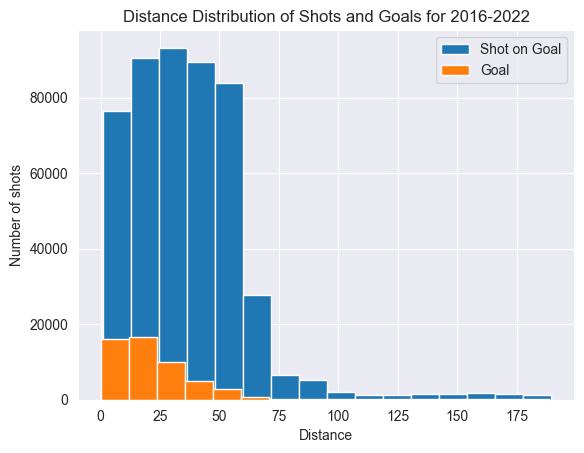

In [42]:
# Histogram of shot/goal according to distance
dist_df = distance(train_tidy)

plt.hist(dist_df[dist_df["event_type"]=="shot-on-goal"]["distance"], 16, label="Shot on Goal")
plt.hist(dist_df[dist_df["event_type"]=="goal"]["distance"], 16, label="Goal")

plt.legend()
plt.xlabel("Distance")
plt.ylabel("Number of shots")
plt.title(f"Distance Distribution of Shots and Goals for {train_years[0]}-{train_years[-1]}")
plt.show()

In [26]:
def angles(dataframe) -> pd.DataFrame:
    """
    Modified version of "distance" function from Milestone 1
    Function to add the columns distance and angle to the dataframe.
    Distance is the distance between the goal and the coordinates where the shot was taken
    Angle is the angle of the shot relative to the goal

    Parameters:
        dataframe (pd.DataFrame) : Dataframe of the games

    Returns:
        pd.DataFrame
    """
    df = dataframe.copy()
    # team_defending: True is home_team, False is away_team
    # df["team_id"] contain "eventOwnerTeamId" which is the team associated with the action
    # df["team_id"] is the team that is trying to score
    df["team_defending"] = (df["team_id"] != df["homeTeam_id"])

    df["side_defending"] = df["homeTeamDefendingSide"]

    conditions = [df["side_defending"]=="right",df["side_defending"]=="left"]
    choices = ["left","right"]

    df["side_defending"] = np.where(df["team_defending"]==False,np.select(conditions,choices),df["side_defending"])

    # if right, goal_coor = (89,0)
    # else left, (-89,0)
    df["goalCoordX"] = np.where(df["side_defending"]=="right",89,-89)

    #calculate the distance between the x,y coordinates and the goal
    #the y coordinate for the goals is 0
    df["distance"] = np.sqrt((df["goalCoordX"]-df["x_coord"])**2 + df["y_coord"]**2)

    #
    df["angle"] = np.arctan(df["y_coord"]/(df["goalCoordX"]-df["x_coord"]))

    #Remove team_defending, side_defending, goalCoordX
    #Keep only the distance
    df = df.drop(
        columns = ["team_defending", "side_defending", "goalCoordX"]
    )

    return df

      game_id  event_id    season situation_code  period   time  shooter_id  \
0  2016020001         8  20162017           1551       1  01:11   8478483.0   
1  2016020001        11  20162017           1551       1  02:53   8467967.0   
2  2016020001        15  20162017           1551       1  04:01   8476879.0   
3  2016020001        16  20162017           1551       1  04:46   8474578.0   
4  2016020001        24  20162017           1551       1  06:46   8475716.0   

   scorer_id    event_type  x_coord  ...  player  player_last_name    goalie  \
0        NaN  shot-on-goal    -77.0  ...   Mitch            Marner     Craig   
1        NaN  shot-on-goal     86.0  ...   Chris             Kelly  Frederik   
2        NaN  shot-on-goal     23.0  ...    Cody              Ceci  Frederik   
3        NaN  shot-on-goal     33.0  ...    Erik          Karlsson  Frederik   
4        NaN  shot-on-goal    -34.0  ...  Martin          Marincin     Craig   

   goalie_last_name emptyNet strength away_p

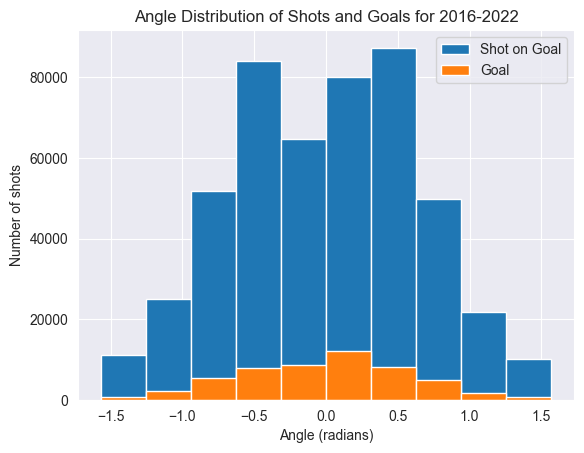

In [46]:
# Histogram for the angles of shots/goals
angles_df = angles(train_tidy)
print(angles_df.head())

#plt.hist(angles_df["angle"], 16, label="Shot on Goal")

plt.hist(angles_df[angles_df["event_type"]=="shot-on-goal"]["angle"], label="Shot on Goal")
plt.hist(angles_df[angles_df["event_type"]=="goal"]["angle"], label="Goal")

plt.legend()
plt.xlabel("Angle (radians)")
plt.ylabel("Number of shots")
plt.title(f"Angle Distribution of Shots and Goals for {train_years[0]}-{train_years[-1]}")
plt.show()

C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-p

[]

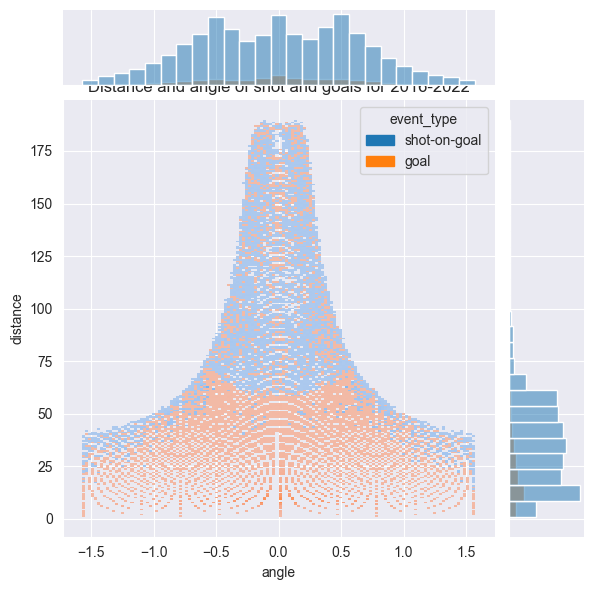

In [47]:
# 2d histogram of angles and distances

#print(angles_df.head())
#print(angles_df[angles_df["distance"].isna()].head())

# Remove missing coords:
angles_df.replace(np.inf, np.nan, inplace=True)
angles_df.dropna(subset=["distance", "angle"], inplace=True)
sns.jointplot(x="angle", y="distance", data=angles_df,  hue="event_type", kind="hist", marginal_kws=dict(bins=25))

plt.title(f"Distance and angle of shot and goals for {train_years[0]}-{train_years[-1]}")
plt.plot()

[]

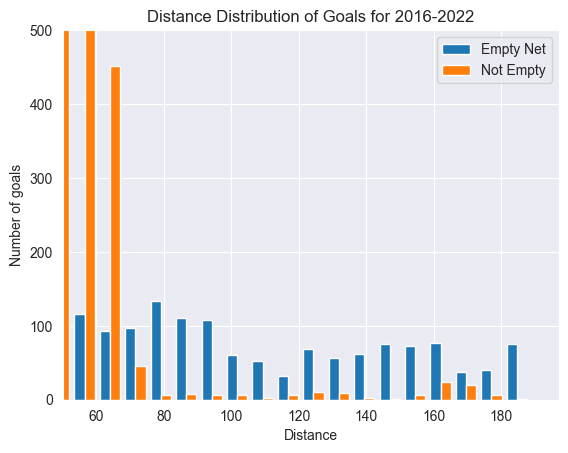

In [65]:
# Figure showing the goals scored from far away when the net is empty vs not

goals = dist_df[dist_df["event_type"]=="goal"]

plt.hist([goals[goals["emptyNet"]==True]["distance"], goals[goals["emptyNet"]==False]["distance"]], 25, histtype="bar", label=["Empty Net", "Not Empty"])
#plt.hist(, 25, label="Not Empty", histtype="bar")

# To see only the goals that are from very far:
plt.xlim(50)
plt.ylim(0,500)

plt.legend()
plt.xlabel("Distance")
plt.ylabel("Number of goals")
plt.title(f"Distance Distribution of Goals for {train_years[0]}-{train_years[-1]}")

plt.plot()

event 657 of 2016020428: no coordinates